# Topic 21 - Data Visualization

## From one table to a picture someone can act on

In Topic 20 you built one analysis-ready table from five raw files, and used it to answer five of the director's questions - in code. That code was correct, but it was not something you could hand to her. A managing director does not read a DataFrame; she needs to see the answer in about five seconds, in a meeting, without you in the room to explain it.

**Data visualization** is the stage that turns a correct table into a chart that makes a finding impossible to miss. It is not decoration on top of the analysis - a badly chosen chart actively hides the finding underneath a technically correct one, and a well-chosen chart can make a finding obvious that was invisible in the table.

This lesson works with the *same* Ghanaian retail distributor from Topic 20 - the same six tables, the same four seeded data-quality problems, the same 2023 trading year. Nothing new to wrangle. Every chart in this lesson answers a question that table could already answer in numbers; the only new skill is choosing the right picture and building it so it reads correctly on its own.

## Learning objectives

By the end of this lesson you should be able to:

- explain the Figure/Axes model that every matplotlib chart is built from;
- choose a chart type from the question being asked, not from habit;
- build bar charts that compare categories correctly: sorted, labelled, one colour per series;
- build line charts that show change over time, with a rolling average to separate signal from noise;
- build histograms and box plots that reveal a distribution's shape, spread, and outliers;
- build scatter plots and a correlation heatmap that test whether two things are actually related;
- use a pie or waffle chart only when it is the right tool, and explain why that is rare;
- use seaborn to get the same charts faster, with better defaults;
- assemble several charts into a single dashboard figure that a non-technical reader can act on in one glance;
- state, for any chart you build, who reads it and what they should do next.

## Analysis compared with visualization

| | Analysis (Topic 20) | Visualization (Topic 21) |
|---|---|---|
| Output | A table of numbers | A picture |
| Audience | You, and other analysts | A manager, in a meeting, without you there to narrate |
| Primary tool | `pandas` | `matplotlib`, `seaborn` |
| A result is right when | The numbers are verified | The numbers are verified **and** the chart reads correctly alone, in five seconds |
| Typical failure | A silent bad join | A chart that is technically correct but misleads anyway |

That last row is the one students underestimate. A dual-axis chart, a rainbow of colours with no meaning, a pie chart with eleven slices - none of these are *wrong* in the sense of containing bad numbers. They are wrong because a reader draws the wrong conclusion from them anyway. Chart-building has its own silent failures, exactly the way joins did in Topic 20, and this lesson spends as much time on what **not** to build as on what to build.

In [1]:
# Run this cell as it is.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker


def find_data_dir():
    """Locate the lesson's data folder from the repository root, the lesson
    folder, or the assignments folder, so this notebook runs from anywhere."""
    candidates = [
        Path.cwd() / "data",
        Path.cwd() / "data_visualization" / "data",
        Path.cwd().parent / "data",
    ]
    for candidate in candidates:
        if (candidate / "orders.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find orders.csv. Expected a data folder containing the six "
        "Topic 20/21 tables. Looked in: " + ", ".join(str(c) for c in candidates)
    )


DATA_DIR = find_data_dir()

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 130)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#e1e0d9"
plt.rcParams["grid.linewidth"] = 0.8
plt.rcParams["axes.edgecolor"] = "#c3c2b7"
plt.rcParams["axes.axisbelow"] = True

# The course palette. Hues are assigned in this fixed order to every chart in
# Topic 21 - never cycled, never re-generated - so a category keeps the same
# colour in every chart it appears in. See 21a for why this matters.
PALETTE = {
    "blue": "#2a78d6", "aqua": "#1baf7a", "yellow": "#eda100", "green": "#008300",
    "violet": "#4a3aa7", "red": "#e34948", "magenta": "#e87ba4", "orange": "#eb6834",
}
MUTED = "#c3c2b7"    # de-emphasis grey, for "everything but the finding"
INK = "#0b0b0b"      # text and value labels

# Fixed colour assignment per category, used throughout this topic.
ZONE_COLOR = {"Coastal": PALETTE["blue"], "Middle": PALETTE["aqua"], "Northern": PALETTE["yellow"]}
CHANNEL_COLOR = {"Field Agent": PALETTE["blue"], "Online": PALETTE["aqua"],
                 "Phone": PALETTE["yellow"], "Shop": PALETTE["green"]}
SEGMENT_COLOR = {"Retail": PALETTE["blue"], "Wholesale": PALETTE["aqua"], "Institution": PALETTE["yellow"]}
CATEGORY_COLOR = {
    "Beverages": PALETTE["blue"], "Grains": PALETTE["aqua"], "Cooking Oils": PALETTE["yellow"],
    "Personal Care": PALETTE["green"], "Household": PALETTE["violet"], "Snacks": PALETTE["red"],
    "Canned Goods": PALETTE["magenta"],
}

print("pandas version:   ", pd.__version__)
print("data folder:      ", DATA_DIR)
print("files:            ", sorted(p.name for p in DATA_DIR.glob("*.csv")))

pandas version:    3.0.6
data folder:       /home/johnny/Projects/itfy-da/data_visualization/data
files:             ['customers.csv', 'monthly_targets_wide.csv', 'orders.csv', 'products.csv', 'regions.csv', 'returns.csv']


In [2]:
# Paste the function you built in Topic 20. This is the same contract: five
# raw tables in, one analysis-ready table out, with its own row-count check.
def clean_region(series):
    return (series.str.strip()
                  .str.replace(r"\s+", " ", regex=True)
                  .str.title())


def build_analysis_table(orders, customers, products, regions, returns):
    """Combine the five raw tables into one analysis-ready table (Topic 20)."""
    expected_rows = len(orders)

    customers = customers.copy()
    customers["region"] = clean_region(customers["region"])
    products = products.drop_duplicates(subset="product_id", keep="first")
    customers = customers.merge(regions, on="region", how="left", validate="m:1")

    table = (orders
             .merge(customers, on="customer_id", how="left", validate="m:1")
             .merge(products, on="product_id", how="left", validate="m:1"))

    returned_ids = set(returns["order_id"])
    table["was_returned"] = table["order_id"].isin(returned_ids)

    table["order_date"] = pd.to_datetime(table["order_date"])
    table["month"] = table["order_date"].dt.strftime("%b")
    table["weekday"] = table["order_date"].dt.day_name()
    table["revenue_ghs"] = (table["quantity"] * table["unit_price_ghs"]).round(2)
    table["cost_ghs"] = (table["quantity"] * table["unit_cost_ghs"]).round(2)
    table["profit_ghs"] = (table["revenue_ghs"] - table["cost_ghs"]).round(2)

    if len(table) != expected_rows:
        raise ValueError(
            f"Row count changed during wrangling: {expected_rows} -> {len(table)}. "
            "A merge has duplicated rows."
        )
    return table.sort_values("order_date").reset_index(drop=True)


orders = pd.read_csv(DATA_DIR / "orders.csv")
customers = pd.read_csv(DATA_DIR / "customers.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
regions = pd.read_csv(DATA_DIR / "regions.csv")
returns = pd.read_csv(DATA_DIR / "returns.csv")
targets_wide = pd.read_csv(DATA_DIR / "monthly_targets_wide.csv")

analysis = build_analysis_table(orders, customers, products, regions, returns)
print(f"Analysis table: {analysis.shape[0]} rows x {analysis.shape[1]} columns")
print(f"Total revenue: GHS {analysis['revenue_ghs'].sum():,.2f}")
print(f"Total profit:  GHS {analysis['profit_ghs'].sum():,.2f}")

Analysis table: 1200 rows x 24 columns
Total revenue: GHS 230,001.08
Total profit:  GHS 65,886.38


---

## The anatomy of a chart

Every matplotlib chart is two objects: a **Figure** (the whole canvas, which can hold several charts) and one or more **Axes** (a single plot, with its own x-axis, y-axis, title, and data). You will see `fig, ax = plt.subplots()` at the top of almost every cell in this lesson - that line creates both objects in one call and hands you `ax` to draw on.

A chart that is ready to hand to someone else has, at minimum: a title that states the finding, axis labels that include units, a legend if there is more than one series, and - for work you did not do yourself the day you present it - a note on where the data came from. Everything else is detail.

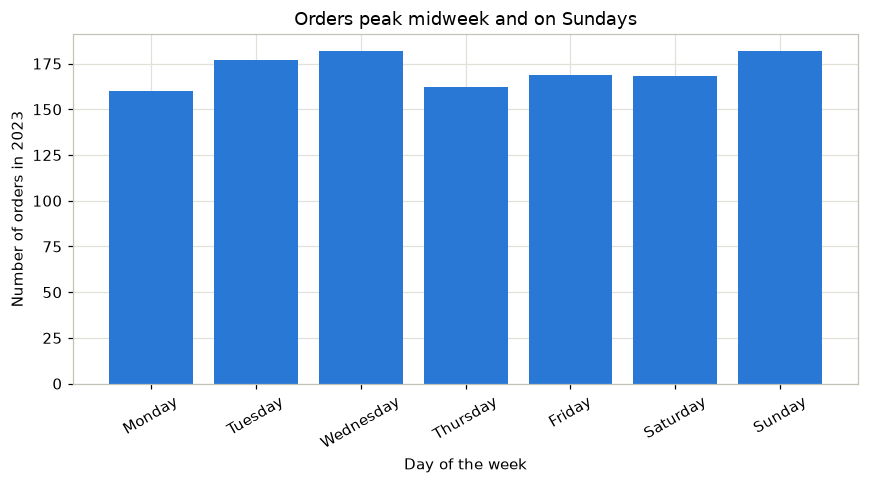

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
orders_by_weekday = analysis["weekday"].value_counts().reindex(weekday_order)

ax.bar(orders_by_weekday.index, orders_by_weekday.values,
       color=PALETTE["blue"])

ax.set_title("Orders peak midweek and on Sundays")
ax.set_xlabel("Day of the week")
ax.set_ylabel("Number of orders in 2023")
ax.tick_params(axis="x", rotation=30)

fig.tight_layout()
plt.show()

Five things happened in that cell that belong in every chart you build from here on:

1. `fig, ax = plt.subplots(...)` - create the canvas and the plot.
2. `ax.bar(...)` - draw the data. One call, one colour, because this is one series (order count) across categories that have no natural ranking - see the chart-selection rule below for why that matters.
3. `ax.set_title(...)` states the finding - "orders peak midweek and on Sundays" - not the generic label "Orders by weekday."
4. `ax.set_xlabel` / `ax.set_ylabel` name the axis **and its unit** ("Number of orders in 2023", not just "Orders").
5. `fig.tight_layout()` before `plt.show()`, so labels do not get clipped.

Section 21a goes through the Figure/Axes model in full, including multi-panel figures with `plt.subplots(rows, cols)` - the thing you will need for the dashboard at the end of this lesson.

---

## The chart-selection rule

Topic 19 and Topic 20 already gave you half of this rule: *line for change over time, bar for comparing categories.* That rule was correct as far as it went. Here is the rest of it.

| Question it answers | Chart | Why |
|---|---|---|
| How do these categories compare? | Bar (sorted, one colour) | Length is the easiest visual quantity for a reader to compare accurately |
| How did one thing change over time? | Line | Position along a continuous axis shows a trend; a bar chart over time hides it in a forest of rectangles |
| What does this distribution look like - where does it cluster, how far does it spread, are there outliers? | Histogram, box plot | Bar and line charts assume one number per category; a distribution is many numbers for *one* category |
| Are two numeric things related? | Scatter plot | The only chart that plots two measures against each other point by point |
| How do many pairs of things relate at once? | Heatmap | A grid of colour reads faster than a grid of numbers, for the same reason a bar reads faster than a table |
| How does a whole break into its parts? | Bar (stacked or sorted) first; pie or waffle only for a single, instantly-read snapshot of five categories or fewer | Comparing slice angles is a harder visual task than comparing bar lengths - see the composition section below |

Two rules sit underneath that table, and they are not optional:

- **One series, one colour.** If a bar chart has one bar per category and the categories have no natural order, every bar gets the *same* colour. Colouring each bar a different hue does not add information - the category names on the axis already identify them - it just spends the reader's attention on nothing. Reach for colour only when colour is doing a second job: telling two or more *series* apart, or marking the one bar that is the finding (see "emphasis" below).
- **Never two y-axes on one plot.** A chart with revenue on the left axis and order count on the right invents a correlation that is not in the data, because the two scales are lined up arbitrarily. If you need to compare two measures of different sizes, use two charts, or index both to a common start point.

---

## Comparing categories: the bar family

Here is the bar chart from the end of Topic 20 - profit by zone, which answered "which zone produced the most profit?"

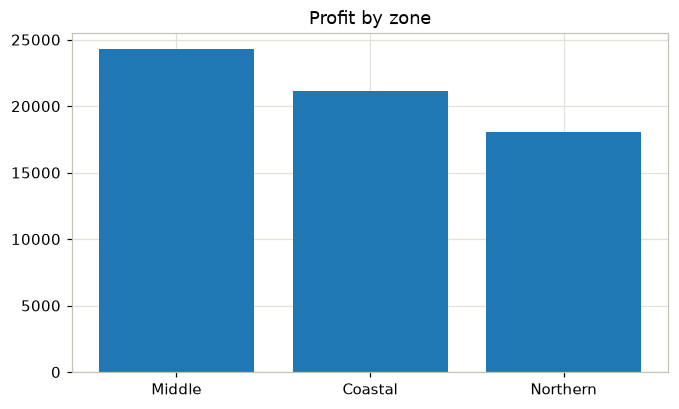

In [4]:
# The Topic 20 version: correct numbers, default styling.
zone_profit = analysis.groupby("zone")["profit_ghs"].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(zone_profit.index, zone_profit.values)
ax.set_title("Profit by zone")
plt.show()

That chart is not wrong. It is also not finished: no units on the axis, a title that describes the chart instead of stating the finding, and no indication of which bar actually matters. Here is the same data, built to the standard the rest of this course now expects - using **emphasis**: colour the one bar that is the finding, and grey out the rest.

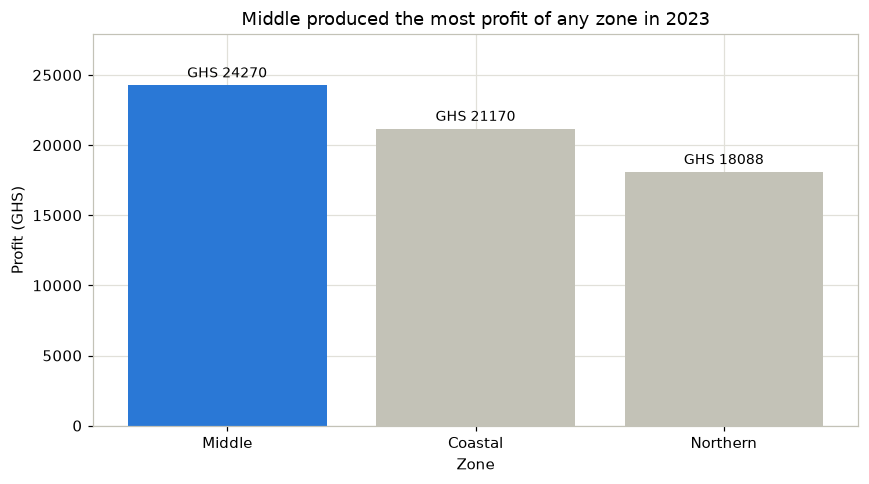

But profit MARGIN tells a different story - highest to lowest:
zone
Northern    29.7
Coastal     28.6
Middle      28.2


In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))

colors = [PALETTE["blue"] if zone == zone_profit.index[0] else MUTED
          for zone in zone_profit.index]
bars = ax.bar(zone_profit.index, zone_profit.values, color=colors)
ax.bar_label(bars, fmt="GHS %.0f", fontsize=9, padding=3)

ax.set_title(f"{zone_profit.index[0]} produced the most profit of any zone in 2023")
ax.set_xlabel("Zone")
ax.set_ylabel("Profit (GHS)")
ax.set_ylim(0, zone_profit.values.max() * 1.15)

fig.tight_layout()
plt.show()

margin = (analysis.groupby("zone").apply(
    lambda g: g["profit_ghs"].sum() / g["revenue_ghs"].sum() * 100, include_groups=False)
    .sort_values(ascending=False))
print("But profit MARGIN tells a different story - highest to lowest:")
print(margin.round(1).to_string())

Read that last line before moving on. Middle produced the most profit in cash terms (GHS 24,269.81), but Northern converted a larger *share* of its revenue into profit (29.7% margin, against Middle's 28.2%). Two bar charts of the same three zones, one answering "who made the most money" and the other "who ran the tightest operation," give two different answers - and a dashboard that shows only one of them is not lying, but it is not telling the whole story either. Section 21b covers grouped bars, stacked bars, and horizontal bars for long category names.

---

## Change over time: the line family

A single line, one colour, is the right chart for "did revenue change over the year?" But a raw monthly line is noisy enough to hide the answer. Adding a rolling average - the technique from Topic 20's window-functions section - separates the trend from the month-to-month wobble.

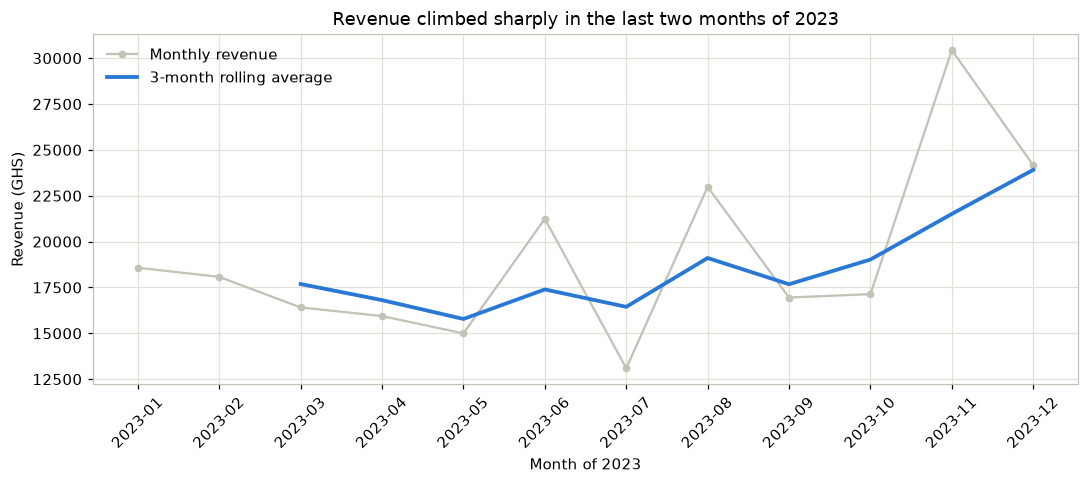

Jan-Oct average:  GHS 17,539.95 per month
Nov-Dec average:  GHS 27,300.78 per month (55.6% higher)


In [6]:
monthly_revenue = (analysis.groupby(analysis["order_date"].dt.to_period("M"))["revenue_ghs"]
                           .sum())
monthly_revenue.index = monthly_revenue.index.astype(str)
rolling_3m = monthly_revenue.rolling(3).mean()

fig, ax = plt.subplots(figsize=(10, 4.5))

ax.plot(monthly_revenue.index, monthly_revenue.values,
        color=MUTED, linewidth=1.5, marker="o", markersize=4, label="Monthly revenue")
ax.plot(monthly_revenue.index, rolling_3m.values,
        color=PALETTE["blue"], linewidth=2.5, label="3-month rolling average")

ax.set_title("Revenue climbed sharply in the last two months of 2023")
ax.set_xlabel("Month of 2023")
ax.set_ylabel("Revenue (GHS)")
ax.tick_params(axis="x", rotation=45)
ax.legend(frameon=False)

fig.tight_layout()
plt.show()

jan_oct = monthly_revenue.iloc[0:10].mean()
nov_dec = monthly_revenue.iloc[10:12].mean()
print(f"Jan-Oct average:  GHS {jan_oct:,.2f} per month")
print(f"Nov-Dec average:  GHS {nov_dec:,.2f} per month ({(nov_dec / jan_oct - 1) * 100:.1f}% higher)")

Notice the colour choice: the raw monthly line is **muted grey** and the rolling average is the one in the course blue, with both labelled in a legend. That is the "emphasis" pattern again, applied to a line chart instead of a bar chart - context in grey, finding in colour. Section 21c covers multi-series lines (one line per zone) and when a rolling window is the wrong tool.

---

## Distributions: histogram and box plot

Every chart so far has plotted one number per category or one number per month. A **distribution** is many numbers for the same thing - every individual order's revenue, for instance - and a bar or line chart cannot show it. A histogram bins the values and counts how many fall in each bin; a box plot summarises the same information as five numbers (minimum, 25th percentile, median, 75th percentile, maximum) that you can compare across groups.

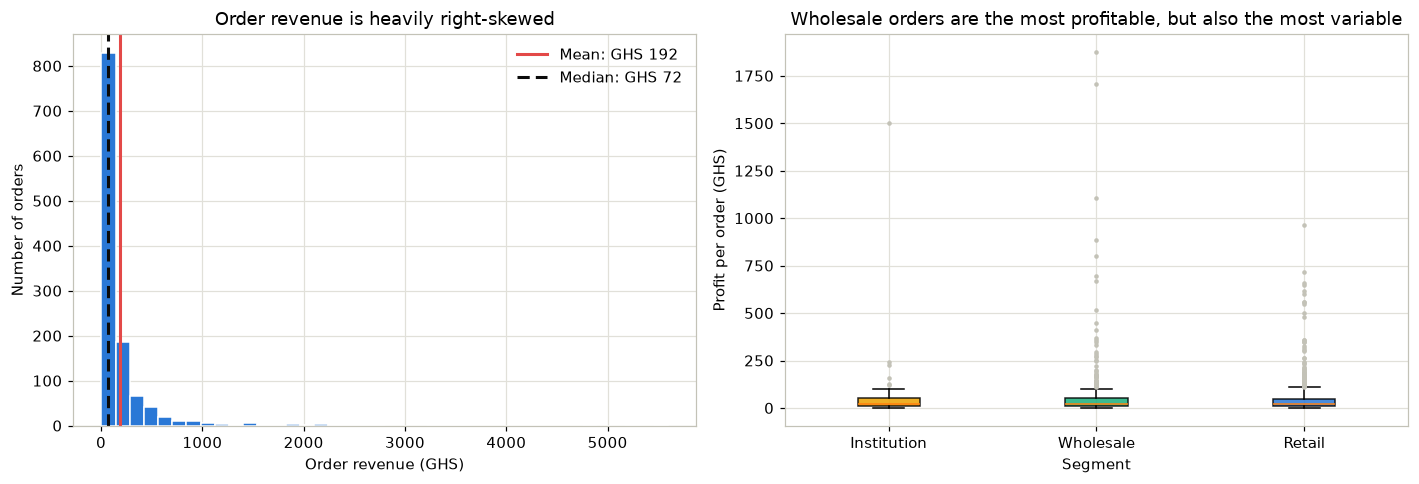

Mean order revenue (GHS 191.67) is more than double the median (GHS 72.16) - a few large orders pull it up.
Orders above GHS 392.52 (the IQR outlier fence): 135 of 1200 (11.2%).


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(analysis["revenue_ghs"], bins=40, color=PALETTE["blue"], edgecolor="white")
axes[0].axvline(analysis["revenue_ghs"].mean(), color=PALETTE["red"], linewidth=2,
                 label=f"Mean: GHS {analysis['revenue_ghs'].mean():,.0f}")
axes[0].axvline(analysis["revenue_ghs"].median(), color=INK, linewidth=2, linestyle=(0, (4, 2)),
                 label=f"Median: GHS {analysis['revenue_ghs'].median():,.0f}")
axes[0].set_title("Order revenue is heavily right-skewed")
axes[0].set_xlabel("Order revenue (GHS)")
axes[0].set_ylabel("Number of orders")
axes[0].legend(frameon=False)

segment_order = ["Institution", "Wholesale", "Retail"]
box_data = [analysis.loc[analysis["segment"] == seg, "profit_ghs"].dropna() for seg in segment_order]
bp = axes[1].boxplot(box_data, tick_labels=segment_order, patch_artist=True, showfliers=True,
                      flierprops={"markersize": 3, "markerfacecolor": MUTED, "markeredgecolor": "none"})
for patch, seg in zip(bp["boxes"], segment_order):
    patch.set_facecolor(SEGMENT_COLOR[seg])
    patch.set_alpha(0.85)
axes[1].set_title("Wholesale orders are the most profitable, but also the most variable")
axes[1].set_xlabel("Segment")
axes[1].set_ylabel("Profit per order (GHS)")

fig.tight_layout()
plt.show()

q1, q3 = analysis["revenue_ghs"].quantile([0.25, 0.75])
fence = q3 + 1.5 * (q3 - q1)
print(f"Mean order revenue (GHS {analysis['revenue_ghs'].mean():,.2f}) is more than double the median "
      f"(GHS {analysis['revenue_ghs'].median():,.2f}) - a few large orders pull it up.")
print(f"Orders above GHS {fence:,.2f} (the IQR outlier fence): "
      f"{(analysis['revenue_ghs'] > fence).sum()} of {len(analysis)} "
      f"({(analysis['revenue_ghs'] > fence).mean() * 100:.1f}%).")

That mean-versus-median gap is the whole reason distributions get their own chart type. If you only ever reported "average order revenue is GHS 191.67," you would be describing a typical order that barely exists - half of all orders are under GHS 72.16. A histogram shows you that shape in one look; a single summary number hides it. Section 21d covers reading a box plot's five numbers precisely and when a log scale helps a skewed histogram.

---

## Relationships: scatter plot and correlation heatmap

A scatter plot tests whether two numeric measures move together. It is also the chart most likely to show you that two things you expected to be related... are not.

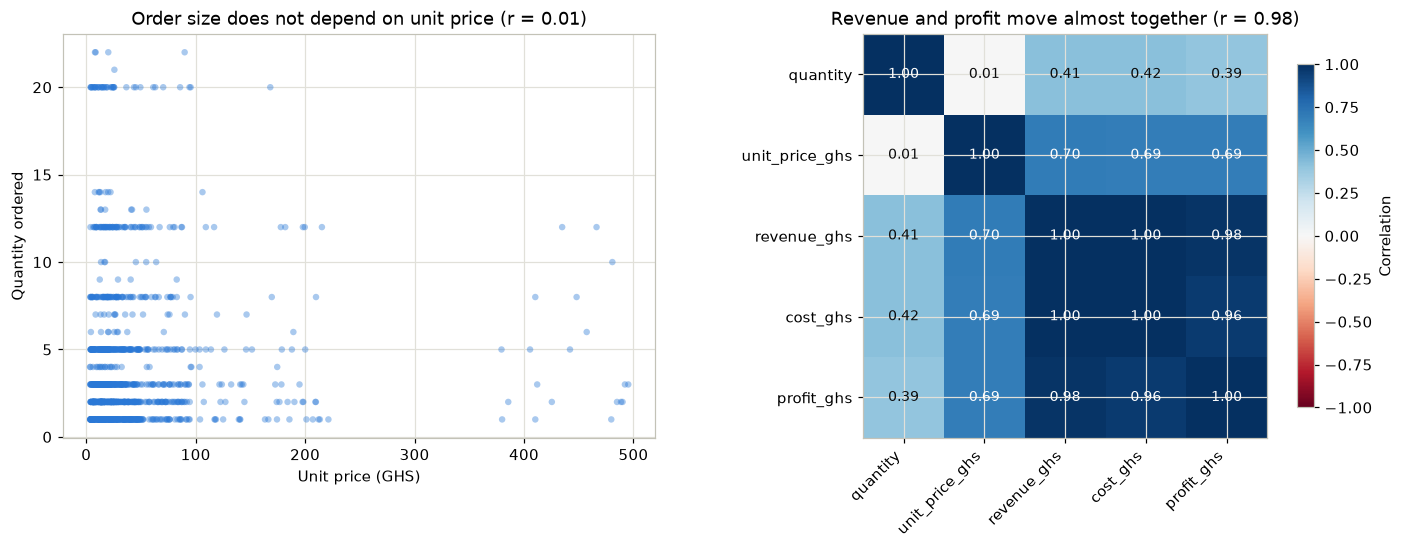

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(analysis["unit_price_ghs"], analysis["quantity"],
                s=18, alpha=0.4, color=PALETTE["blue"], edgecolors="none")
r_qp = analysis["quantity"].corr(analysis["unit_price_ghs"])
axes[0].set_title(f"Order size does not depend on unit price (r = {r_qp:.2f})")
axes[0].set_xlabel("Unit price (GHS)")
axes[0].set_ylabel("Quantity ordered")

numeric_cols = ["quantity", "unit_price_ghs", "revenue_ghs", "cost_ghs", "profit_ghs"]
corr = analysis[numeric_cols].corr()
im = axes[1].imshow(corr, cmap="RdBu", vmin=-1, vmax=1)
axes[1].set_xticks(range(len(numeric_cols)))
axes[1].set_yticks(range(len(numeric_cols)))
axes[1].set_xticklabels(numeric_cols, rotation=45, ha="right")
axes[1].set_yticklabels(numeric_cols)
for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        axes[1].text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center",
                      color="white" if abs(corr.iloc[i, j]) > 0.6 else INK, fontsize=9)
axes[1].set_title("Revenue and profit move almost together (r = 0.98)")
fig.colorbar(im, ax=axes[1], shrink=0.85, label="Correlation")

fig.tight_layout()
plt.show()

Two choices in that heatmap are deliberate, not default. First, the colour scale runs from **-1 to +1** even though every value here happens to be positive - correlation is a signed measure, and fixing the scale lets a reader compare this heatmap to any other one honestly. Second, the colour map is **diverging** (blue to white to red) rather than a single hue, because zero correlation is a meaningful midpoint ("no relationship"), not just a low value. Section 21e covers bubble charts (a third, size-encoded variable) and reshaping a table into the wide grid a heatmap needs.

---

## Composition charts, used sparingly

A pie or waffle chart answers "how does a whole break into its parts," in a single glance, for a small number of parts. That is a real, narrow job - and most of the time a sorted bar chart does that job better, because comparing bar *lengths* is a task the human eye is good at, while comparing slice *angles* is a task it is measurably worse at. The channel mix below is a legitimate case: four categories, genuinely summing to 100% of 2023 revenue, read once as a snapshot.

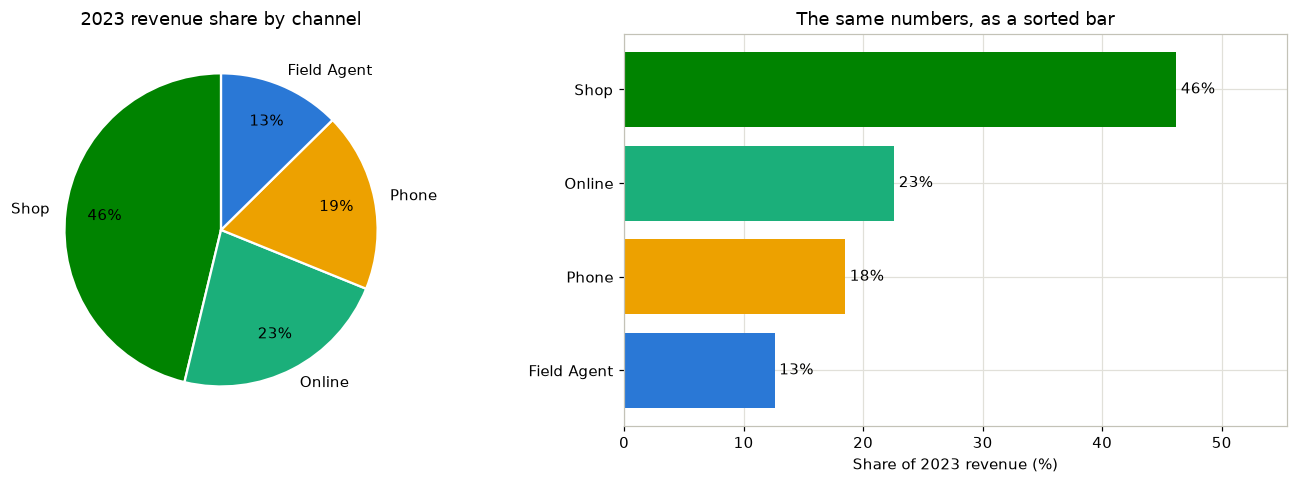

In [9]:
channel_share = (analysis.groupby("channel")["revenue_ghs"].sum()
                  .pipe(lambda s: s / s.sum() * 100).round(1)
                  .sort_values(ascending=False))
colors = [CHANNEL_COLOR[ch] for ch in channel_share.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].pie(channel_share.values, labels=channel_share.index, colors=colors,
            autopct="%1.0f%%", startangle=90, pctdistance=0.75,
            wedgeprops={"edgecolor": "white", "linewidth": 1.5})
axes[0].set_title("2023 revenue share by channel")

bars = axes[1].barh(channel_share.index[::-1], channel_share.values[::-1],
                     color=[CHANNEL_COLOR[ch] for ch in channel_share.index[::-1]])
axes[1].bar_label(bars, fmt="%.0f%%", padding=3)
axes[1].set_title("The same numbers, as a sorted bar")
axes[1].set_xlabel("Share of 2023 revenue (%)")
axes[1].set_xlim(0, channel_share.max() * 1.2)

fig.tight_layout()
plt.show()

Look at the two charts side by side and ask yourself honestly which one let you rank the four channels faster. For most readers it is the bar on the right, even though the pie is not wrong. This is why the chart-selection rule above puts composition last, and gates it at "five categories or fewer" - a seven-slice pie (try it on the product categories) stops being readable as *anything*.

A **waffle chart** - a grid of squares, one square per percentage point - is the other composition option, and it has one advantage a pie does not: it survives being printed in black and white, using hatch patterns instead of colour.

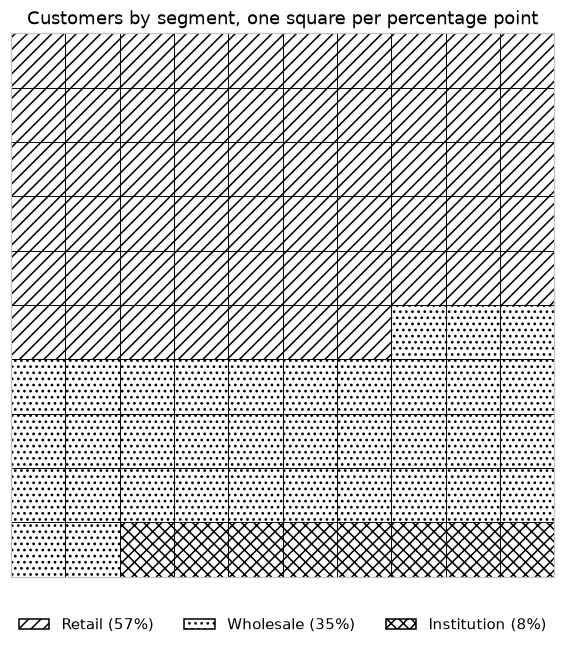

In [10]:
segment_share = (customers["segment"].value_counts(normalize=True) * 100).round(0).astype(int)
segment_share = segment_share.sort_values(ascending=False)

hatches = ["///", "...", "xxx"]
fig, ax = plt.subplots(figsize=(6, 6))
rows, cols = 10, 10
square = 0
for (label, pct), hatch in zip(segment_share.items(), hatches):
    for _ in range(pct):
        r, c = divmod(square, cols)
        ax.add_patch(plt.Rectangle((c, rows - 1 - r), 1, 1, facecolor="white",
                                    edgecolor="black", hatch=hatch, linewidth=0.6))
        square += 1

handles = [plt.Rectangle((0, 0), 1, 1, facecolor="white", edgecolor="black", hatch=h)
           for h in hatches]
ax.legend(handles, [f"{label} ({pct}%)" for label, pct in segment_share.items()],
          loc="upper center", bbox_to_anchor=(0.5, -0.05), ncol=3, frameon=False)
ax.set_xlim(0, cols)
ax.set_ylim(0, rows)
ax.set_aspect("equal")
ax.set_xticks([])
ax.set_yticks([])
ax.set_title("Customers by segment, one square per percentage point")
fig.tight_layout()
plt.show()

Reach for hatch patterns instead of colour whenever the chart has to survive without colour - a black-and-white printout, a photocopy, or a reader with colour-vision deficiency who cannot tell your blue bar from your red one. It is not a style choice to use by default; it is an accessibility fallback to have ready. Section 21f covers both chart types in full, including when a waffle chart is a worse choice than the bar you already know how to build.

---

## Seaborn: the same charts, faster

`seaborn` is a layer on top of matplotlib that knows about DataFrames and groups, so charts that took several lines above take one. It does not replace anything you just learned - a seaborn chart is still a matplotlib Figure and Axes underneath, and everything about titles, labels, and colour choice above still applies.

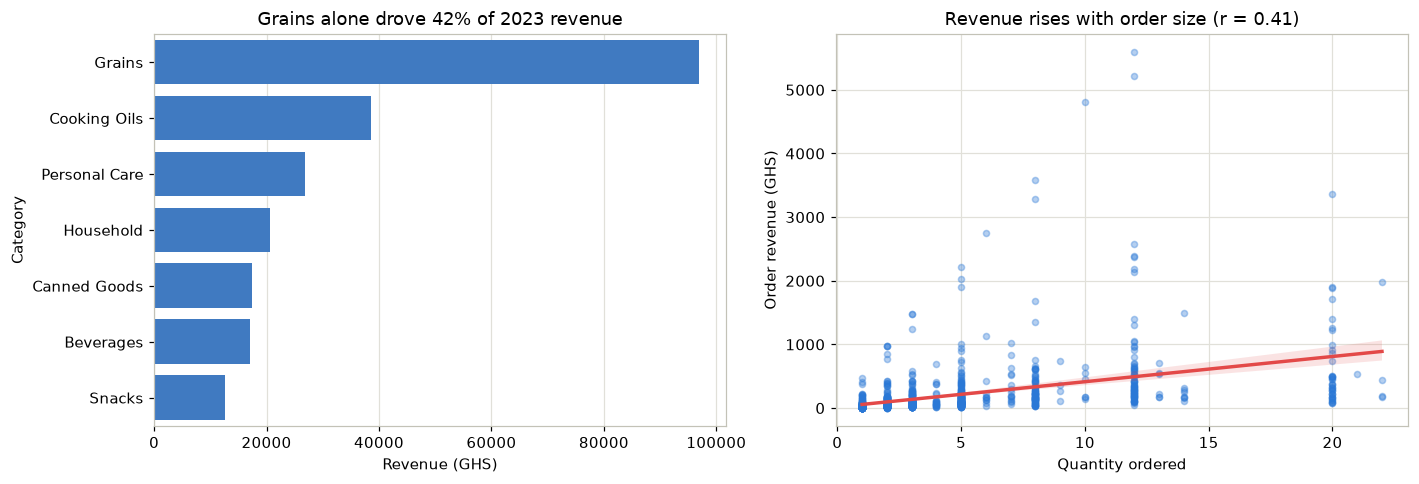

In [11]:
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

category_revenue = analysis.groupby("category")["revenue_ghs"].sum().sort_values(ascending=False)
sns.barplot(x=category_revenue.values, y=category_revenue.index, ax=axes[0],
            color=PALETTE["blue"])
axes[0].set_title("Grains alone drove 42% of 2023 revenue")
axes[0].set_xlabel("Revenue (GHS)")
axes[0].set_ylabel("Category")

sns.regplot(data=analysis, x="quantity", y="revenue_ghs", ax=axes[1],
            scatter_kws={"s": 16, "alpha": 0.35, "color": PALETTE["blue"]},
            line_kws={"color": PALETTE["red"]})
axes[1].set_title(f"Revenue rises with order size (r = {analysis['quantity'].corr(analysis['revenue_ghs']):.2f})")
axes[1].set_xlabel("Quantity ordered")
axes[1].set_ylabel("Order revenue (GHS)")

fig.tight_layout()
plt.show()

`sns.barplot` took one line to do what the earlier bar charts needed several for, and `sns.regplot` added a fitted trend line to a scatter plot for free. The trade-off: seaborn makes its own styling decisions unless you override them, which is why every chart above still sets its own colour explicitly from `PALETTE` rather than letting seaborn pick. Section 21f covers `sns.set_theme()`, seaborn's categorical and statistical plot types, and building a multi-panel figure with seaborn charts inside matplotlib's `subplots()` grid.

---

## Put it together: the director's dashboard

Four charts, four different chart types, one figure - because the director's questions span comparison, time, and performance against target, and no single chart type answers all three.

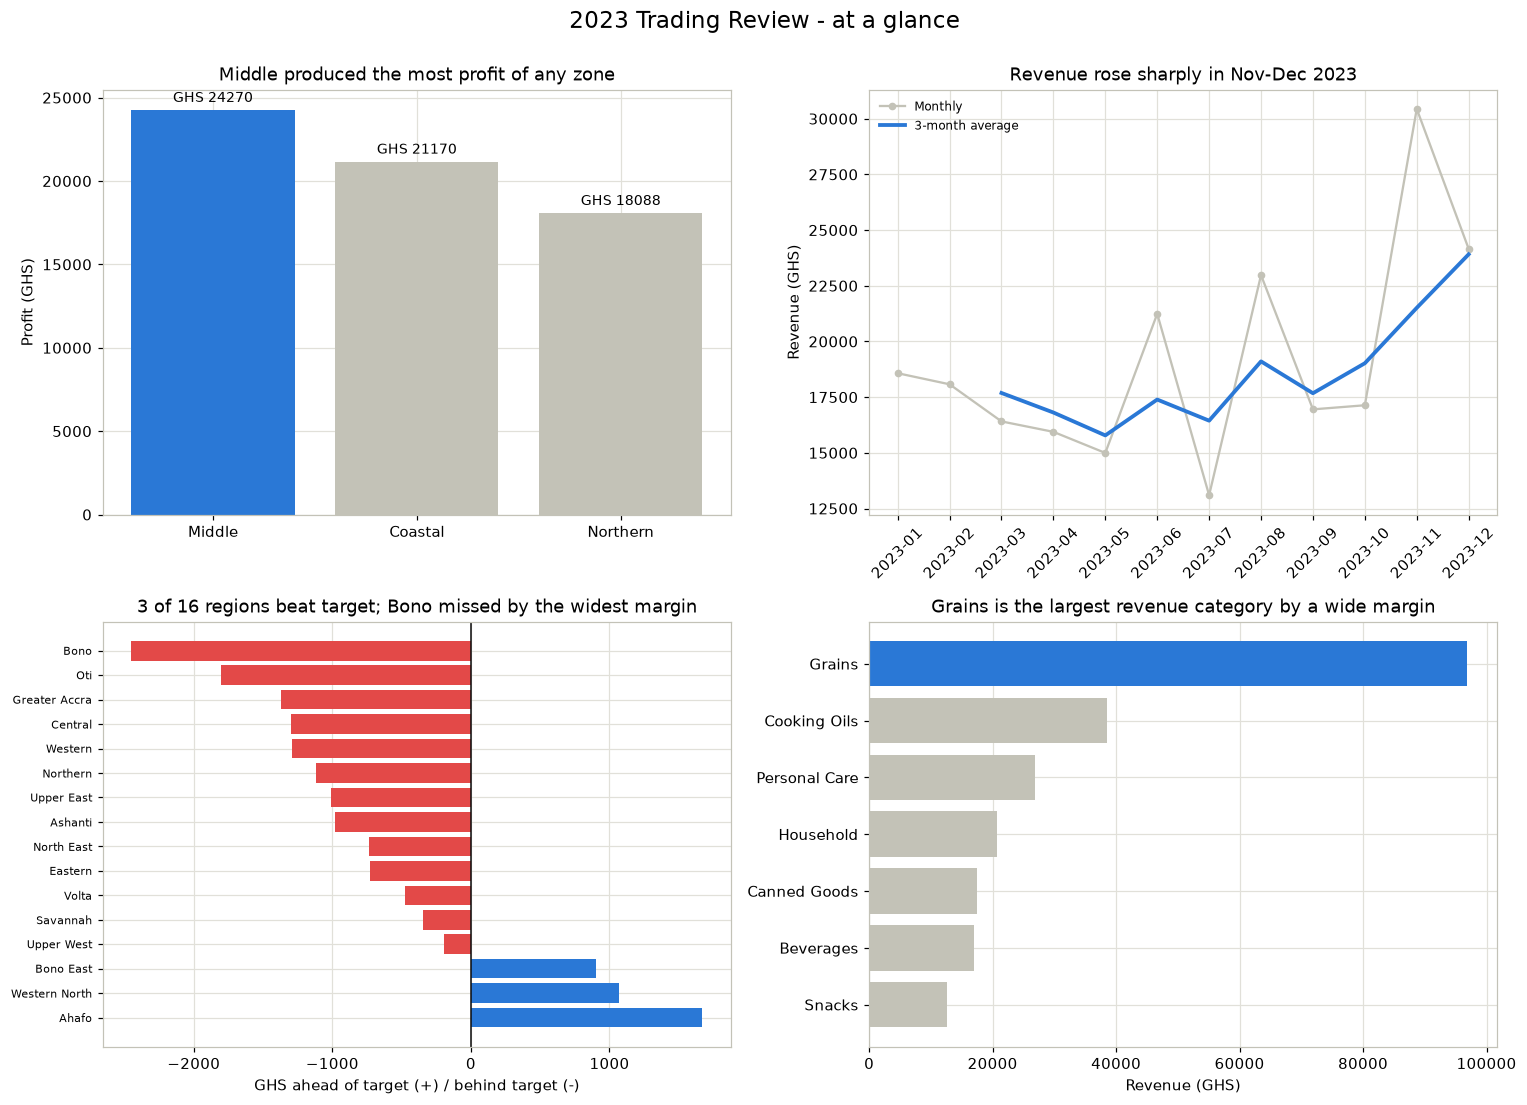

Saved to charts/director_dashboard.png


In [12]:
# Panel data, reusing Topic 20's reshaping and this lesson's chart selection.
targets_long = targets_wide.melt(id_vars="region", var_name="month", value_name="target_ghs")
actual_by_region_month = analysis.groupby(["region", "month"])["revenue_ghs"].sum().reset_index()
perf = targets_long.merge(actual_by_region_month, on=["region", "month"], how="left", validate="1:1")
perf["revenue_ghs"] = perf["revenue_ghs"].fillna(0.0)

region_annual = (perf.groupby("region")[["target_ghs", "revenue_ghs"]].sum())
region_annual["shortfall_ghs"] = (region_annual["target_ghs"] - region_annual["revenue_ghs"]).round(2)
region_annual = region_annual.sort_values("shortfall_ghs", ascending=True)  # most-ahead first

category_revenue = analysis.groupby("category")["revenue_ghs"].sum().sort_values(ascending=True)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Profit by zone, emphasis on the leader.
zone_profit = analysis.groupby("zone")["profit_ghs"].sum().sort_values(ascending=False)
colors = [PALETTE["blue"] if z == zone_profit.index[0] else MUTED for z in zone_profit.index]
bars = axes[0, 0].bar(zone_profit.index, zone_profit.values, color=colors)
axes[0, 0].bar_label(bars, fmt="GHS %.0f", fontsize=9, padding=3)
axes[0, 0].set_title("Middle produced the most profit of any zone")
axes[0, 0].set_ylabel("Profit (GHS)")

# 2. Monthly revenue with rolling average.
monthly_revenue = analysis.groupby(analysis["order_date"].dt.to_period("M"))["revenue_ghs"].sum()
monthly_revenue.index = monthly_revenue.index.astype(str)
axes[0, 1].plot(monthly_revenue.index, monthly_revenue.values, color=MUTED,
                 marker="o", markersize=4, linewidth=1.5, label="Monthly")
axes[0, 1].plot(monthly_revenue.index, monthly_revenue.rolling(3).mean().values,
                 color=PALETTE["blue"], linewidth=2.5, label="3-month average")
axes[0, 1].set_title("Revenue rose sharply in Nov-Dec 2023")
axes[0, 1].set_ylabel("Revenue (GHS)")
axes[0, 1].tick_params(axis="x", rotation=45)
axes[0, 1].legend(frameon=False, fontsize=8)

# 3. Region performance against target - diverging.
colors = [PALETTE["red"] if v > 0 else PALETTE["blue"] for v in region_annual["shortfall_ghs"]]
axes[1, 0].barh(region_annual.index, -region_annual["shortfall_ghs"], color=colors)
axes[1, 0].axvline(0, color=INK, linewidth=1)
axes[1, 0].set_title("3 of 16 regions beat target; Bono missed by the widest margin")
axes[1, 0].set_xlabel("GHS ahead of target (+) / behind target (-)")
axes[1, 0].tick_params(axis="y", labelsize=7)

# 4. Category revenue, sorted, emphasis on the leader.
colors = [PALETTE["blue"] if c == category_revenue.index[-1] else MUTED for c in category_revenue.index]
bars = axes[1, 1].barh(category_revenue.index, category_revenue.values, color=colors)
axes[1, 1].set_title("Grains is the largest revenue category by a wide margin")
axes[1, 1].set_xlabel("Revenue (GHS)")

fig.suptitle("2023 Trading Review - at a glance", fontsize=15, y=1.0)
fig.tight_layout()

charts_dir = Path("charts")
charts_dir.mkdir(exist_ok=True)
fig.savefig(charts_dir / "director_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Saved to {charts_dir / 'director_dashboard.png'}")

Every panel in that figure is a chart type this lesson already justified: emphasis bar, line-with-rolling-average, diverging bar, sorted horizontal bar. Nothing in it is a pie, a dual axis, or a rainbow of unexplained colours. That restraint is the point - a dashboard is not "put every chart you know how to make on one page," it is "pick the four chart types that each answer one real question, and say no to the rest."

---

## Key takeaways

- **A chart has to read correctly alone**, in five seconds, without you in the room - that is a harder bar than "the numbers are correct."
- Every chart is a **Figure** and one or more **Axes**; `fig, ax = plt.subplots()` is the line you will write most often in this topic.
- The chart-selection rule: **bar** for comparing categories, **line** for change over time, **histogram/box** for a distribution's shape, **scatter** for a relationship between two numbers, **heatmap** for many relationships at once, **pie/waffle** only for a single snapshot of five categories or fewer.
- **One series, one colour**, when categories have no natural order. Colour is for telling series apart or marking the finding - not decoration.
- **Emphasis** - one bar or line in the course colour, everything else in grey - is usually a better choice than a different hue per category.
- **Never two y-axes on one plot.** It invents a correlation that is not in the data.
- A **correlation heatmap** is a diverging chart (fix the scale at -1 to +1), because zero is a meaningful midpoint, not just a low value.
- **Mean and median can tell different stories.** A histogram shows you the shape a single summary number hides.
- A pie or waffle chart is the exception, not the default - a sorted bar almost always makes the same comparison easier to read.
- `seaborn` builds the same matplotlib Figure/Axes faster, with statistical extras like a fitted regression line - it does not replace anything you learned about titles, labels, or colour.
- A **dashboard** is a small, deliberate set of chart types, each answering one real question - not every chart you can make, arranged on one page.

## Further reading and the course path

### matplotlib and seaborn documentation
- [matplotlib: Quick start guide](https://matplotlib.org/stable/users/explain/quick_start.html)
- [matplotlib: `pyplot.subplots`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html)
- [matplotlib: Choosing colormaps](https://matplotlib.org/stable/users/explain/colors/colormaps.html)
- [seaborn: An introduction](https://seaborn.pydata.org/tutorial/introduction.html)
- [seaborn: Choosing color palettes](https://seaborn.pydata.org/tutorial/color_palettes.html)

### Background
- [Edward Tufte, "The Visual Display of Quantitative Information"](https://www.edwardtufte.com/tufte/books_vdqi) - the data-ink ratio and why chart-junk costs more than it looks like it does
- [Cole Nussbaumer Knaflic, "Storytelling with Data"](https://www.storytellingwithdata.com/) - on choosing a chart for the audience, not the data

### Practice notebooks for this topic
- [21a - Anatomy of a chart](topic21a_anatomy_of_a_chart.ipynb)
- [21b - Comparing categories](topic21b_comparing_categories.ipynb)
- [21c - Change over time](topic21c_change_over_time.ipynb)
- [21d - Distributions](topic21d_distributions.ipynb)
- [21e - Relationships](topic21e_relationships.ipynb)
- [21f - Composition and seaborn](topic21f_composition_and_seaborn.ipynb)
- [21g - Visualization practice](topic21g_visualization_practice.ipynb)

### Assignment
- [Topic 21 assignment - the director's dashboard](assignments/topic21_assignment_trading_dashboard.ipynb)

### Elsewhere in the course
- [Topic 19 - Data gathering](../data_analysis_process/topic19_data_gathering.ipynb)
- [Topic 20 - Data wrangling](../data_wrangling/topic20_data_wrangling.ipynb)
- [Submitting your work with GitHub](../data_analysis_process/topic19d_appendix_submitting_with_github.ipynb)